In [6]:
import h5py
import os

# bfm relative path
bfm_h5_path = "../models/BFM17/model2017-1_face12_nomouth.h5"

if not os.path.exists(bfm_h5_path):
    print(f"Error: File not found at {bfm_h5_path}")
else:
    print(f"File found at {bfm_h5_path}")

with h5py.File(bfm_h5_path, "r") as f:
    print("Datasets and groups in the file:")

    def print_dataset(name, obj):
        if isinstance(obj, h5py.Dataset):
            print(f"  Dataset: {name}, Shape: {obj.shape}, Type: {obj.dtype}")
        elif isinstance(obj, h5py.Group):
            print(f"  Group: {name}")

    f.visititems(print_dataset)

    try:
        shape_mean = f["shape/model/mean"][:]
        shape_pca = f["shape/model/pcaBasis"][:]
        shape_variance = f["shape/model/pcaVariance"][:]

        print(f"\nShape mean loaded, Shape: {shape_mean.shape}")
        print(f"Shape PCA basis loaded, Shape: {shape_pca.shape}")
        print(f"Shape PCA variance loaded, Shape: {shape_variance.shape}")
    except KeyError as e:
        print(f"Error: {str(e)}")

File found at ../models/BFM17/model2017-1_face12_nomouth.h5
Datasets and groups in the file:
  Group: catalog
  Group: catalog/MorphableModel
  Dataset: catalog/MorphableModel/modelPath, Shape: (1,), Type: |S1
  Dataset: catalog/MorphableModel/modelType, Shape: (1,), Type: |S12
  Group: catalog/MorphableModel.color
  Dataset: catalog/MorphableModel.color/modelPath, Shape: (1,), Type: |S6
  Dataset: catalog/MorphableModel.color/modelType, Shape: (1,), Type: |S23
  Group: catalog/MorphableModel.expression
  Dataset: catalog/MorphableModel.expression/modelPath, Shape: (1,), Type: |S11
  Dataset: catalog/MorphableModel.expression/modelType, Shape: (1,), Type: |S23
  Group: catalog/MorphableModel.shape
  Dataset: catalog/MorphableModel.shape/modelPath, Shape: (1,), Type: |S7
  Dataset: catalog/MorphableModel.shape/modelType, Shape: (1,), Type: |S18
  Group: color
  Group: color/model
  Dataset: color/model/mean, Shape: (85764,), Type: float32
  Dataset: color/model/noiseVariance, Shape: (1,

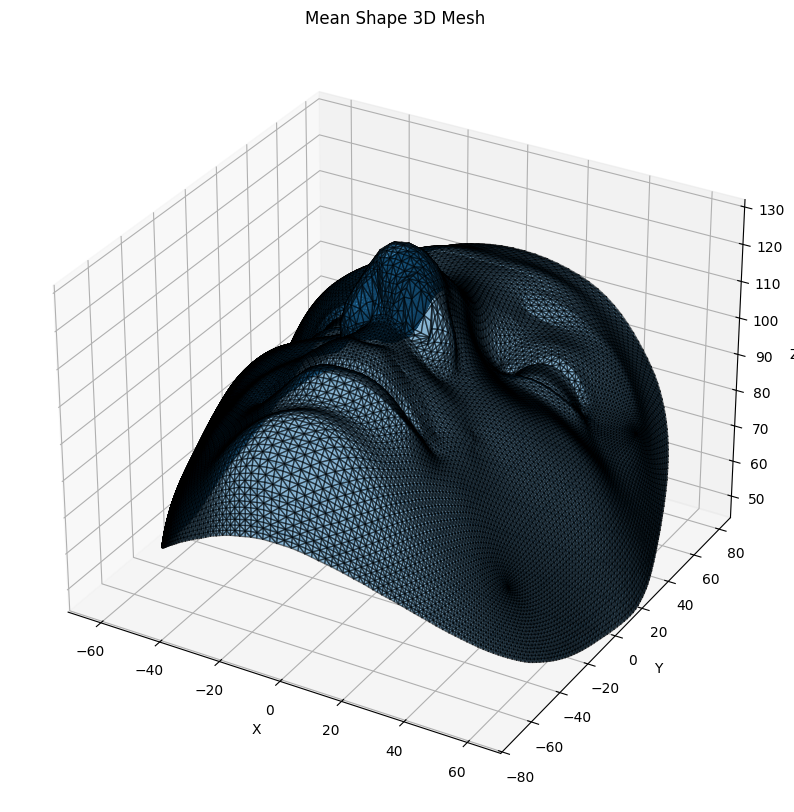

In [ ]:
import h5py
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d.art3d import Poly3DCollection

with h5py.File(bfm_h5_path, "r") as f:
    shape_mean = f["shape/model/mean"][:]
    triangles = f["shape/representer/cells"][:].T

vertices = shape_mean.reshape(-1, 3)


def visualize_3d_mesh(vertices, triangles, title="3D Mesh Model"):
    fig = plt.figure(figsize=(10, 10))
    ax = fig.add_subplot(111, projection="3d")

    mesh = Poly3DCollection(vertices[triangles], alpha=0.5, edgecolor="k")
    ax.add_collection3d(mesh)

    ax.set_xlim(vertices[:, 0].min(), vertices[:, 0].max())
    ax.set_ylim(vertices[:, 1].min(), vertices[:, 1].max())
    ax.set_zlim(vertices[:, 2].min(), vertices[:, 2].max())

    ax.set_title(title)
    ax.set_xlabel("X")
    ax.set_ylabel("Y")
    ax.set_zlabel("Z")
    plt.show()


visualize_3d_mesh(vertices, triangles, title="Mean Shape 3D Mesh")